# E-Commerce Sales Forecasting & Peak Sales Analysis


In [ ]:
# 0. Imports & configuration
import os, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)

CSV_PATH      = "brazilian_ecommerce_data.csv"
MODEL_PATH    = "sales_forecast_model.pkl"
TARGET        = "revenue"      
TEST_MONTHS   = 4              
EXCLUDE_STATUS = ["canceled", "unavailable"]

In [ ]:
if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        up = files.upload()
        CSV_PATH = list(up.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"Place {CSV_PATH} next to this notebook.")

df = pd.read_csv(CSV_PATH, parse_dates=["order_purchase_timestamp"], encoding="utf-8-sig")
print("Shape:", df.shape)
print("Date range:", df.order_purchase_timestamp.min(), "->", df.order_purchase_timestamp.max())
df.head(3)

Shape: (112650, 17)
Date range: 2016-09-04 21:15:19 -> 2018-09-03 09:06:57


,order_id,order_item_id,product_id,order_status,product_category,product_name_lenght,product_description_lenght,product_photos_qty,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,price,freight_value,review_score,review_creation_date,review_comment_title,review_comment_message
0,e481f51cbdc54678b7cc49136f2d6af7,1,87285b34884572647811a353c7ac498a,delivered,housewares,40.0,268.0,4.0,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18 00:00:00,29.99,8.72,4.0,2017-10-11 00:00:00,NaN,"Não testei o produto ainda, mas ele veio corre..."
1,53cdb2fc8bc7dce0b6741e2150273451,1,595fac2a385ac33a80bd5114aec74eb8,delivered,perfumery,29.0,178.0,1.0,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13 00:00:00,118.70,22.76,4.0,2018-08-08 00:00:00,Muito boa a loja,Muito bom o produto.
2,47770eb9100c2d0c44946d9cf07ec65d,1,aa4383b373c6aca5d8797843e5594415,delivered,auto,46.0,232.0,1.0,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04 00:00:00,159.90,19.22,5.0,2018-08-18 00:00:00,NaN,NaN


## 2. Light preparation for modelling
Only the columns needed for time-series work are used, so missing values in review/product-metadata columns don't matter here.
Canceled/unavailable orders are removed because they are not realised sales.

In [ ]:
def prepare_orders(df):
    d = df[["order_id", "order_status", "product_category",
            "order_purchase_timestamp", "price", "freight_value"]].copy()
    d = d[~d["order_status"].isin(EXCLUDE_STATUS)]
    d = d.dropna(subset=["order_purchase_timestamp", "price"])
    d["month"] = d["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()
    return d

orders = prepare_orders(df)
print(f"Rows kept: {len(orders):,} of {len(df):,}")
orders.groupby("month").size().rename("items").to_frame().T

Rows kept: 112,101 of 112,650


month,2016-09-01,2016-10-01,2016-12-01,2017-01-01,2017-02-01,2017-03-01,2017-04-01,2017-05-01,2017-06-01,2017-07-01,...,2017-12-01,2018-01-01,2018-02-01,2018-03-01,2018-04-01,2018-05-01,2018-06-01,2018-07-01,2018-08-01,2018-09-01
items,5,342,1,953,1936,2975,2660,4106,3571,4493,...,6300,8173,7597,8195,7957,7898,7060,7039,7216,1


## 3. Temporal aggregation (monthly) & coverage check
The raw data contains **sparse/partial months** (Sep–Dec 2016 has almost no orders (and Nov 2016 none at all); Sep 2018 has a single order).
Fitting a trend line through those points would badly distort the slope, so the modelling window is restricted to **one contiguous block of complete months (Jan 2017 – Aug 2018)**.

In [ ]:
def monthly_aggregate(orders):
    m = (orders.groupby("month")
               .agg(revenue=("price", "sum"),
                    items_sold=("price", "size"),
                    n_orders=("order_id", "nunique"),
                    avg_item_price=("price", "mean"))
               .asfreq("MS"))
    m["avg_order_value"] = m["revenue"] / m["n_orders"]
    return m

monthly_all = monthly_aggregate(orders)

START_MONTH, MIN_ORDERS = "2017-01-01", 100
valid = monthly_all.loc[START_MONTH:].copy()
valid = valid[valid["n_orders"] >= MIN_ORDERS]         
assert valid.index.to_series().diff().dropna().dt.days.between(28, 31).all(), "gap in months"
print("Modelling window:", valid.index.min().date(), "->", valid.index.max().date(), f"({len(valid)} months)")
excluded = monthly_all.index.difference(valid.index)
print("Excluded sparse/partial months:", [d.strftime('%Y-%m') for d in excluded])
valid

Modelling window: 2017-01-01 -> 2018-08-01 (20 months)
Excluded sparse/partial months: ['2016-09', '2016-10', '2016-11', '2016-12', '2018-09']


,revenue,items_sold,n_orders,avg_item_price,avg_order_value
month,,,,,
2017-01-01,120098.27,953.0,787.0,126.021270,152.602630
2017-02-01,244959.35,1936.0,1718.0,126.528590,142.584022
2017-03-01,368341.32,2975.0,2617.0,123.812208,140.749454
2017-04-01,353842.98,2660.0,2377.0,133.023677,148.861161
2017-05-01,503159.19,4106.0,3640.0,122.542423,138.230547
2017-06-01,429916.61,3571.0,3205.0,120.391098,134.139348
2017-07-01,492287.30,4493.0,3946.0,109.567616,124.756031
2017-08-01,568245.79,4882.0,4272.0,116.396106,133.016337
2017-09-01,621415.91,4815.0,4227.0,129.058341,147.011098


## 4. Feature engineering


In [5]:
def add_features(m):
    m = m.copy()
    m["time_idx"] = np.arange(len(m))
    m["month_num"] = m.index.month
    m["quarter"] = m.index.quarter
    m["is_black_friday_month"] = (m.index.month == 11).astype(int)
    m["lag_1"] = m[TARGET].shift(1)
    m["rolling_3"] = m[TARGET].shift(1).rolling(3).mean()
    return m

data = add_features(valid)
data[[TARGET, "time_idx", "month_num", "quarter", "is_black_friday_month", "lag_1", "rolling_3"]].head(8)

,revenue,time_idx,month_num,quarter,is_black_friday_month,lag_1,rolling_3
month,,,,,,,
2017-01-01,120098.27,0,1,1,0,NaN,NaN
2017-02-01,244959.35,1,2,1,0,120098.27,NaN
2017-03-01,368341.32,2,3,1,0,244959.35,NaN
2017-04-01,353842.98,3,4,2,0,368341.32,244466.313333
2017-05-01,503159.19,4,5,2,0,353842.98,322381.216667
2017-06-01,429916.61,5,6,2,0,503159.19,408447.830000
2017-07-01,492287.30,6,7,3,0,429916.61,428972.926667
2017-08-01,568245.79,7,8,3,0,492287.30,475121.033333


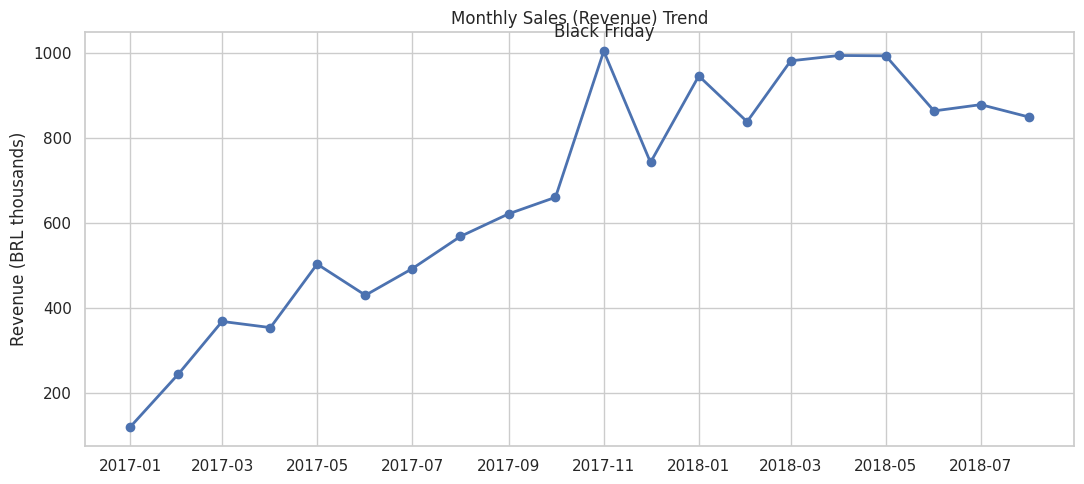

In [ ]:
fig, ax = plt.subplots()
ax.plot(data.index, data[TARGET] / 1e3, marker="o", lw=2)
ax.set_title("Monthly Sales (Revenue) Trend")
ax.set_ylabel("Revenue (BRL thousands)")
nov = data.index[data.index.month == 11]
for d in nov:
    ax.annotate("Black Friday", (d, data.loc[d, TARGET]/1e3), textcoords="offset points", xytext=(0, 10), ha="center")
plt.tight_layout(); plt.show()

## 5. Time-based train/test split


In [ ]:
FEATURES = ["lag_1"]                         
model_df = data.dropna(subset=FEATURES)  

train, test = model_df.iloc[:-TEST_MONTHS], model_df.iloc[-TEST_MONTHS:]
X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]
print(f"Train: {train.index.min():%Y-%m} -> {train.index.max():%Y-%m} ({len(train)} months)")
print(f"Test : {test.index.min():%Y-%m} -> {test.index.max():%Y-%m} ({len(test)} months)")

Train: 2017-02 -> 2018-04 (15 months)
Test : 2018-05 -> 2018-08 (4 months)


## 6. Train & evaluate


In [ ]:
def evaluate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return {"MAE":  float(mean_absolute_error(y_true, y_pred)),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2":   float(r2_score(y_true, y_pred)),
            "MAPE %": float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)}

def recursive_forecast(model, last_value, steps):
    """Forecast `steps` months ahead, feeding each prediction back in as the next month's lag."""
    out, v = [], float(last_value)
    for _ in range(steps):
        v = float(model.predict(pd.DataFrame({"lag_1": [v]}))[0])
        out.append(v)
    return np.array(out)

model = LinearRegression().fit(X_train, y_train)
pred_train = model.predict(X_train)
pred_1step = model.predict(X_test)                                            
pred_rec   = recursive_forecast(model, train[TARGET].iloc[-1], len(test))  

metrics = pd.DataFrame({
    "Train": evaluate(y_train, pred_train),
    "Test: next-month (1-step)": evaluate(y_test, pred_1step),
    "Test: 4 months ahead (recursive)": evaluate(y_test, pred_rec),
}).round(3)
print(f"Equation: revenue(t) = {model.intercept_:,.0f} + {model.coef_[0]:.3f} x revenue(t-1)")
metrics

Equation: revenue(t) = 171,306 + 0.809 x revenue(t-1)


,Train,Test: next-month (1-step),Test: 4 months ahead (recursive)
MAE,90512.750,42540.187,68306.381
RMSE,127629.794,58749.905,74894.501
R2,0.734,-0.062,-0.726
MAPE %,13.602,4.872,7.855


In [ ]:
base_time = LinearRegression().fit(train[["time_idx"]], y_train)
compare = pd.DataFrame({
    "LR on time_idx (previous model)":  evaluate(y_test, base_time.predict(test[["time_idx"]])),
    "Naive: repeat last month":          evaluate(y_test, test["lag_1"]),
    "LR on lag_1: next-month (1-step)":  evaluate(y_test, pred_1step),
    "LR on lag_1: 4 months ahead":       evaluate(y_test, pred_rec),
}).round(2)
compare

,LR on time_idx (previous model),Naive: repeat last month,LR on lag_1: next-month (1-step),LR on lag_1: 4 months ahead
MAE,268289.19,43572.59,42540.19,68306.38
RMSE,290756.92,66836.40,58749.91,74894.50
R2,-25.01,-0.37,-0.06,-0.73
MAPE %,30.78,5.05,4.87,7.85


In [ ]:
tscv = TimeSeriesSplit(n_splits=4, test_size=2)
rows = []
for i, (tr, te) in enumerate(tscv.split(model_df), 1):
    m = LinearRegression().fit(model_df.iloc[tr][FEATURES], model_df.iloc[tr][TARGET])
    r = evaluate(model_df.iloc[te][TARGET], m.predict(model_df.iloc[te][FEATURES]))
    rows.append({"fold": i, "train_months": len(tr), **r})
cv = pd.DataFrame(rows).set_index("fold").round(2)
print("Mean CV MAE:", round(cv.MAE.mean()), "| Mean CV MAPE %:", round(cv["MAPE %"].mean(), 1))
cv

Mean CV MAE: 81679 | Mean CV MAPE %: 8.7


,train_months,MAE,RMSE,R2,MAPE %
fold,,,,,
1,11,124962.48,158786.07,-7.72,13.40
2,13,116859.31,125927.89,-402.25,11.87
3,15,64511.43,79587.16,-0.51,7.34
4,17,20383.37,20398.00,-0.95,2.36


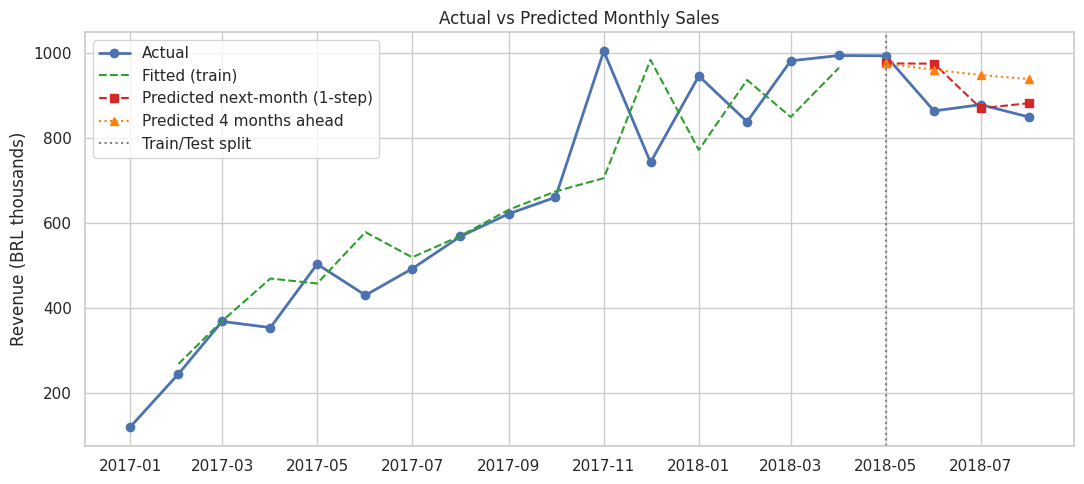

In [ ]:
fig, ax = plt.subplots()
ax.plot(data.index, data[TARGET]/1e3, marker="o", label="Actual", lw=2)
ax.plot(train.index, pred_train/1e3, "--", label="Fitted (train)", color="tab:green")
ax.plot(test.index, pred_1step/1e3, "s--", label="Predicted next-month (1-step)", color="tab:red")
ax.plot(test.index, pred_rec/1e3, "^:", label="Predicted 4 months ahead", color="tab:orange")
ax.axvline(test.index[0], color="gray", ls=":", label="Train/Test split")
ax.set_title("Actual vs Predicted Monthly Sales"); ax.set_ylabel("Revenue (BRL thousands)")
ax.legend(); plt.tight_layout(); plt.show()

## 7. Peak sales period identification
Peaks are computed on the **full** history (all months with data in the modelling window) so the patterns reflect real purchasing behaviour.

In [ ]:
win = orders[(orders["month"] >= valid.index.min()) & (orders["month"] <= valid.index.max())].copy()

ords = (win.groupby("order_id")
           .agg(ts=("order_purchase_timestamp", "first"), revenue=("price", "sum"))
           .reset_index())
ords["month_name"] = ords.ts.dt.month_name()
ords["dow"] = ords.ts.dt.day_name()
ords["hour"] = ords.ts.dt.hour

dow_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

# (a) Peak months — YoY-fair view: only calendar months present in BOTH years (Jan-Aug)
mm = ords.groupby(ords.ts.dt.to_period("M")).agg(orders=("order_id","count"), revenue=("revenue","sum"))
top_months = mm.sort_values("revenue", ascending=False).head(5)
print("Top 5 months by revenue:"); print(top_months.round(0))

# (b) Day of week, (c) Hour of day
by_dow  = ords.groupby("dow").agg(orders=("order_id","count"), revenue=("revenue","sum")).reindex(dow_order)
by_hour = ords.groupby("hour").agg(orders=("order_id","count"), revenue=("revenue","sum"))

print("\nPeak weekday :", by_dow.orders.idxmax(), f"({by_dow.orders.max():,} orders)")
print("Weakest day  :", by_dow.orders.idxmin(), f"({by_dow.orders.min():,} orders)")
print("Peak hour    :", by_hour.orders.idxmax(), "h", f"({by_hour.orders.max():,} orders)")
top_hours = by_hour.orders.nlargest(3).index.tolist()
print("Top 3 hours  :", top_hours)

Top 5 months by revenue:
         orders    revenue
ts                        
2017-11    7421  1003862.0
2018-04    6919   993593.0
2018-05    6833   992872.0
2018-03    7168   981051.0
2018-01    7187   945456.0

Peak weekday : Monday (15,933 orders)
Weakest day  : Saturday (10,725 orders)
Peak hour    : 16 h (6,575 orders)
Top 3 hours  : [16, 11, 14]


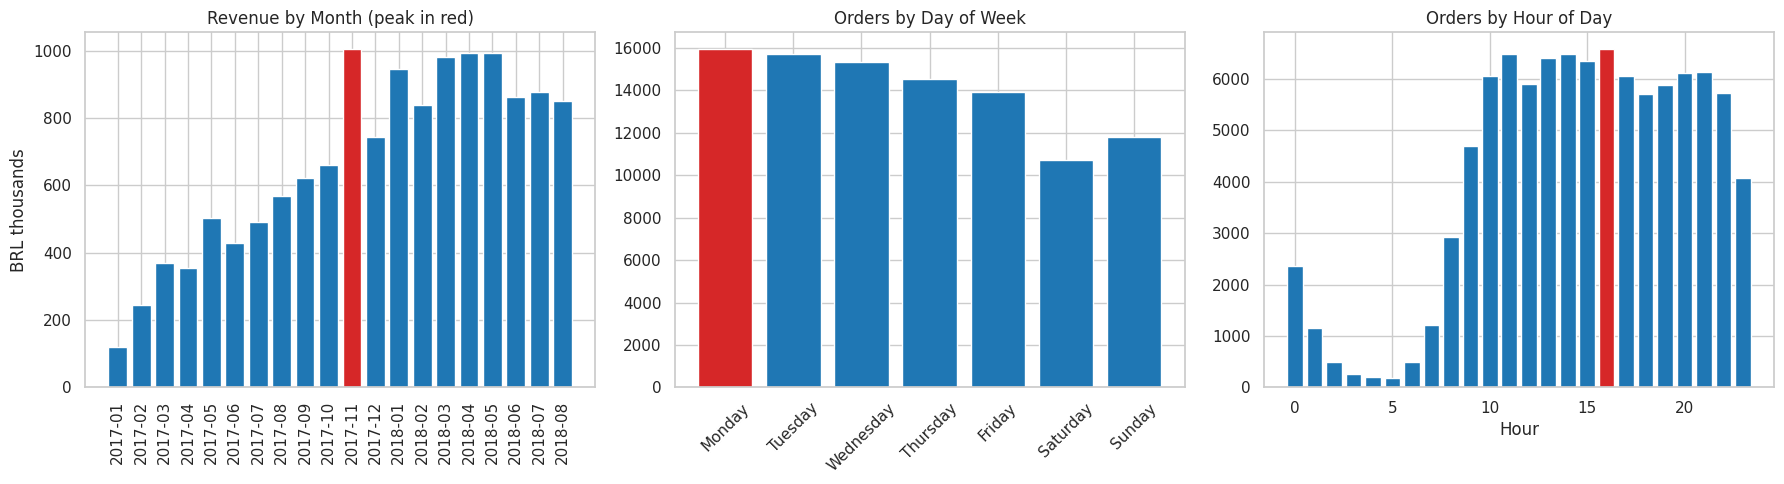

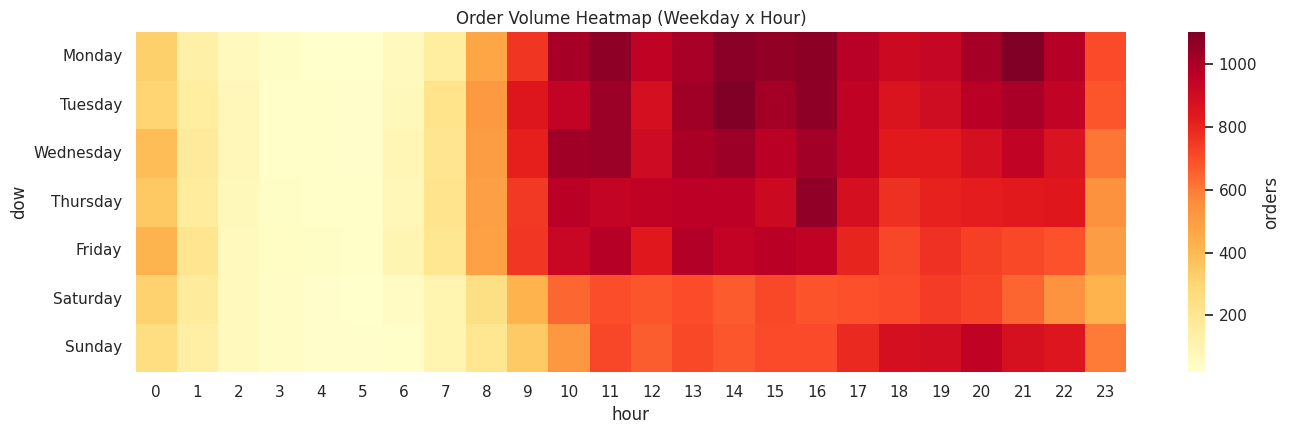

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# Months
mm_plot = mm.copy(); mm_plot.index = mm_plot.index.astype(str)
colors = ["tab:red" if v == mm_plot.revenue.max() else "tab:blue" for v in mm_plot.revenue]
axes[0].bar(mm_plot.index, mm_plot.revenue/1e3, color=colors)
axes[0].set_title("Revenue by Month (peak in red)"); axes[0].tick_params(axis="x", rotation=90)
axes[0].set_ylabel("BRL thousands")
# Day of week
colors = ["tab:red" if v == by_dow.orders.max() else "tab:blue" for v in by_dow.orders]
axes[1].bar(by_dow.index, by_dow.orders, color=colors)
axes[1].set_title("Orders by Day of Week"); axes[1].tick_params(axis="x", rotation=45)
# Hour
colors = ["tab:red" if v == by_hour.orders.max() else "tab:blue" for v in by_hour.orders]
axes[2].bar(by_hour.index, by_hour.orders, color=colors)
axes[2].set_title("Orders by Hour of Day"); axes[2].set_xlabel("Hour")
plt.tight_layout(); plt.show()

# Day x Hour heatmap
heat = ords.pivot_table(index="dow", columns="hour", values="order_id", aggfunc="count").reindex(dow_order)
plt.figure(figsize=(14, 4.5))
sns.heatmap(heat, cmap="YlOrRd", cbar_kws={"label": "orders"})
plt.title("Order Volume Heatmap (Weekday x Hour)"); plt.tight_layout(); plt.show()

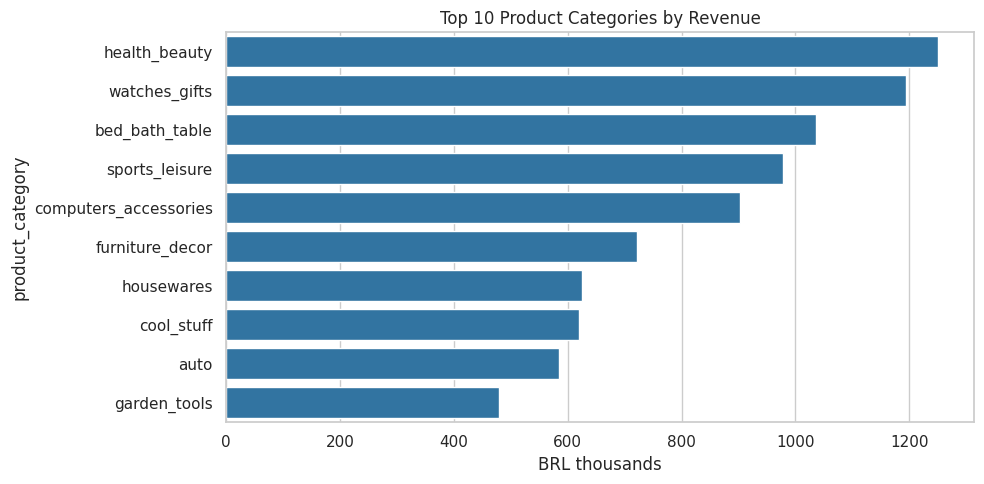

,revenue,items
product_category,,
health_beauty,1251146.0,9585
watches_gifts,1194825.0,5965
bed_bath_table,1035485.0,11089
sports_leisure,977729.0,8573
computers_accessories,902923.0,7760
furniture_decor,721584.0,8229
housewares,625539.0,6903
cool_stuff,619724.0,3772
auto,585177.0,4195


In [ ]:
top_cat = (win.groupby("product_category")["price"].agg(["sum", "count"])
              .rename(columns={"sum": "revenue", "count": "items"})
              .sort_values("revenue", ascending=False).head(10))
plt.figure(figsize=(10, 5))
sns.barplot(x=top_cat.revenue/1e3, y=top_cat.index, color="tab:blue")
plt.title("Top 10 Product Categories by Revenue"); plt.xlabel("BRL thousands"); plt.tight_layout(); plt.show()
top_cat.round(0)

## 8. Final model: refit on all data & forecast the coming months

In [ ]:
final_model = LinearRegression().fit(model_df[FEATURES], model_df[TARGET])
resid_std   = float(np.std(model_df[TARGET] - final_model.predict(model_df[FEATURES]), ddof=2))

last_month  = data.index.max()
last_actual = float(data[TARGET].iloc[-1])
HORIZON     = 6
path   = recursive_forecast(final_model, last_actual, HORIZON)
months = pd.date_range(last_month + pd.offsets.MonthBegin(1), periods=HORIZON, freq="MS")

mae_1   = metrics.loc["MAE", "Test: next-month (1-step)"]
mae_rec = metrics.loc["MAE", "Test: 4 months ahead (recursive)"]
err     = np.array([mae_1] + [mae_rec] * (HORIZON - 1))         

forecast = float(path[0])
lo, hi   = forecast - 1.96 * resid_std, forecast + 1.96 * resid_std
long_run = final_model.intercept_ / (1 - final_model.coef_[0])

fc_table = pd.DataFrame({"forecast": path.round(0), "realistic_low": (path - err).round(0),
                         "realistic_high": (path + err).round(0)}, index=months.strftime("%Y-%m"))
print(f"Last actual month ({last_month:%b %Y}): R$ {last_actual:,.0f}")
print(f"Forecast {months[0]:%B %Y}: R$ {forecast:,.0f}  (approx. 95% range: R$ {lo:,.0f} - {hi:,.0f})")
print(f"Realistic margin (hold-out MAE): +/- R$ {mae_1:,.0f} next month, +/- R$ {mae_rec:,.0f} further out")
print(f"Long-run level the model drifts toward: R$ {long_run:,.0f}")
fc_table

Last actual month (Aug 2018): R$ 848,860
Forecast September 2018: R$ 846,980  (approx. 95% range: R$ 606,225 - 1,087,736)
Realistic margin (hold-out MAE): +/- R$ 42,540 next month, +/- R$ 68,306 further out
Long-run level the model drifts toward: R$ 840,185


,forecast,realistic_low,realistic_high
2018-09,846980.0,804440.0,889520.0
2018-10,845508.0,777201.0,913814.0
2018-11,844354.0,776048.0,912661.0
2018-12,843451.0,775144.0,911757.0
2019-01,842743.0,774437.0,911050.0
2019-02,842189.0,773883.0,910495.0


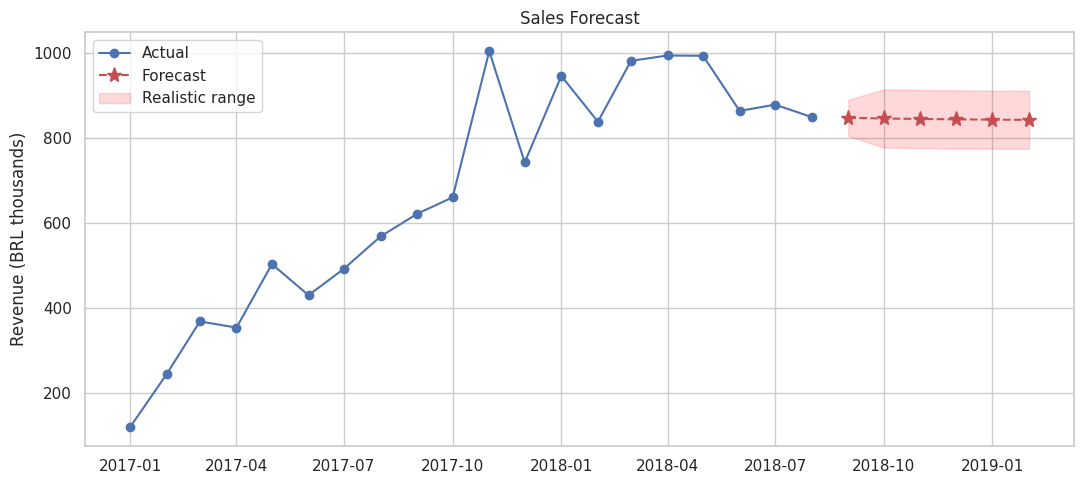

In [16]:
fig, ax = plt.subplots()
ax.plot(data.index, data[TARGET]/1e3, marker="o", label="Actual")
ax.plot(months, path/1e3, "r*--", ms=11, label="Forecast")
ax.fill_between(months, (path-err)/1e3, (path+err)/1e3, color="red", alpha=0.15, label="Realistic range")
ax.set_title("Sales Forecast"); ax.set_ylabel("Revenue (BRL thousands)")
ax.legend(); plt.tight_layout(); plt.show()

## 9. Save the model (`.pkl`)

In [ ]:
artifact = {
    "model": final_model,
    "model_type": "lag_1",
    "features": FEATURES,
    "target": TARGET,
    "first_month": data.index.min(),
    "last_training_month": last_month,
    "last_actual": last_actual,                      
    "residual_std": resid_std,
    "test_metrics": metrics["Test: next-month (1-step)"].to_dict(),
    "test_metrics_recursive": metrics["Test: 4 months ahead (recursive)"].to_dict(),
    "forecast_next_month": {"month": months[0], "revenue": forecast, "lower_95": lo, "upper_95": hi},
}
joblib.dump(artifact, MODEL_PATH)
print("Saved ->", MODEL_PATH)

def predict_months(artifact, steps=1, last_actual=None):
    v = artifact["last_actual"] if last_actual is None else float(last_actual)
    return recursive_forecast(artifact["model"], v, steps)

loaded = joblib.load(MODEL_PATH)
print("Reload check:", f"R$ {predict_months(loaded, 1)[0]:,.0f}")
try:
    from google.colab import files; files.download(MODEL_PATH)
except ImportError:
    pass

Saved -> sales_forecast_model.pkl
Reload check: R$ 846,980
